# SAE "Analyse automatique de données" -- Notebook 4 : régression linéaire

Dans ce notebook, vous devez :
1. Effectuer des expérimentations pour optimiser les paramètres du modèle de régression linéaire ;
2. Rédiger une synthèse pour justifier des pré-traitements effectués et des valeurs des paramètres obtenus pour vos modèles de régression. Vous concluerez sur le meilleur choix des pré-traitements et des paramètres de votre ou vos modèles.

	
Vous pouvez également tout d'abord considérer un sous-ensemble de votre ensemble d'apprentissage, pour mettre au point chacune de vos expérimentations.
			


## Modules python utilisés

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error, r2_score, root_mean_squared_error
import math
import spacy
import numpy as np


## 1. Régression linéaire

In [4]:
#Df d'apprentissage
x_train = pd.read_csv('data/train_test/x_train.csv',  index_col=0)
y_train = pd.read_csv('data/train_test/y_train.csv',  index_col=0)

#Df de test
x_test = pd.read_csv('data/train_test/x_test.csv',  index_col=0)
y_test = pd.read_csv('data/train_test/y_test.csv',  index_col=0)


In [ ]:
# Spacy

# Charge la langue - anglais
# Attention: Nous avons choisi la version sm de la bibliothèque, la version trf peut être prise cependant elle plus volumineuse et plus lente
nlp = spacy.load("en_core_web_sm")

def cleanData(doc):
    doc = doc.lower()
    doc = nlp(doc)
    tokens_utiles = [
        token.lemma_.lower() for token in doc
        if not token.is_stop and not token.is_punct 
        and token.pos_ in ["ADJ","ADV","VERB",""] # 
    ]
    
    return " ".join(tokens_utiles)

def cleanAllData(docs):
    clean_data = []
    for doc in docs:
        clean_data.append(cleanData(doc))

print(cleanData(x_train['text_'].iloc[0]))


x_train['text_'] = x_train['text_'].map(lambda x: cleanData(x))
x_train['text_'].replace("", np.nan, inplace=True)

avant_dropNa = len(x_train)
x_train = x_train.dropna(subset=['text_'])
apres_dropNa = len(x_train)

print(f"Traitement spacy terminé {avant_dropNa - apres_dropNa} lignes vides supprimés ")

/home/lev/.local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


buy good good
Traitement spacy terminé 0 lignes vides supprimés 


/tmp/ipykernel_7034/849274845.py:27: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  x_train['text_'].replace("", np.nan, inplace=True)


### 1.1 Régression avec le texte - Linear Regression

In [8]:
# On défini les différents transformeurs 
processeur = ColumnTransformer(
    remainder='drop',
    transformers=[
        ('review', TfidfVectorizer(
            max_features=5000, # Garder les X termes plus importants
            min_df=10, # Ignorer les mots avec une rareté inférieur à 10
            ngram_range=(1,2), # Capte les expressions de 2 mots monogramme et bigramme
            stop_words='english'), 
         'text_'),
    ]
)

print(f"Processeur : {processeur.remainder}")

model = Pipeline([
    ('preprocessor', processeur),
    ('classifier', LinearRegression())
])

reg = model.fit(X=x_train,y=y_train)

prediction = reg.predict(x_test)

mse = mean_squared_error(y_test,prediction)

print(f"Mse: {mse}")
print(f"RMSE: {math.sqrt(mse)}")

plt.scatter(y_test, prediction, color='blue', alpha=0.1)

plt.plot([1, 5], [1, 5], color='red', linestyle='--', linewidth=2, label='Idéal')

plt.title('Prédictions vs Réalité')
plt.xlabel('Vraies Notes')
plt.ylabel('Notes Prédites')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)


Processeur : drop


ValueError: np.nan is an invalid document, expected byte or unicode string.

### 1.2 Régression avec le texte - Ridge

Processeur : drop
Mse: 1.4428948025832875
RMSE: 1.2012055621679778


'\n Les paramères utilisés:\n\n'

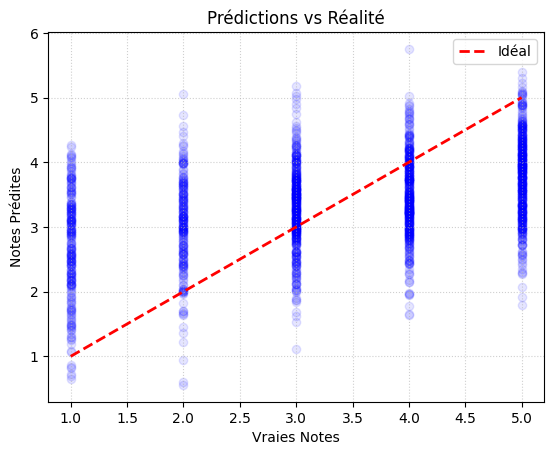

In [6]:
# On défini les différents transformeurs 
processeur = ColumnTransformer(
    remainder='drop',
    transformers=[
        ('review', TfidfVectorizer(max_features=5000, # Garder les X termes plus importants
            min_df=10, # Ignorer les mots avec une rareté inférieur à 5
            ngram_range=(1,2), # Capte les expressions de 2 mots
            stop_words='english'), 
         'text_'),
    ]
)

print(f"Processeur : {processeur.remainder}")

model = Pipeline([
    ('preprocessor', processeur),
    ('classifier', Ridge())
])

reg = model.fit(X=x_train,y=y_train)

prediction = reg.predict(x_test)

mse = mean_squared_error(y_test,prediction)

print(f"Mse: {mse}")
print(f"RMSE: {math.sqrt(mse)}")


plt.scatter(y_test, prediction, color='blue', alpha=0.1)

plt.plot([1, 5], [1, 5], color='red', linestyle='--', linewidth=2, label='Idéal')

plt.title('Prédictions vs Réalité')
plt.xlabel('Vraies Notes')
plt.ylabel('Notes Prédites')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)

"""
 Les paramères utilisés:

"""

## 2. Synthèse des expérimentations et des résultats obtenus